# 05 — Audit MovieLens per benchmark cold-start (rating e utenti)

**Obiettivo:** stabilire se il catalogo **effettivamente arricchito in TMDb** consente il protocollo discusso con Matteo: per ogni utente di test, **10 rating di profilo**, rivelati progressivamente (0, 1, 3, 5, 10), e **20 rating nascosti**, fissi all'interno della simulazione, come ground truth.

Questo notebook **non addestra** Matrix Factorization, non costruisce risposte LLM, non prepara gli embedding e **non modifica i notebook precedenti**. Produce un audit riproducibile, alcuni campionamenti *diagnostici* e file riepilogativi utili per decidere se procedere.

### Domande cui risponde

1. Quanti rating/utenti rimangono filtrando sul **catalogo realmente presente** in `dataset_enriched_movielens_tmdb.csv`?
2. Quanti utenti hanno almeno **30 rating** nel catalogo? Come si distribuiscono fra positivi (≥4), intermedi (2,5–3,5) e negativi (≤2)?
3. Campionando **senza guardare ai target**, quanto spesso 20 rating nascosti contengono almeno 3/5 preferenze positive?
4. Il catalogo e i suoi film rimangono sufficientemente coperti da un training con **utenti distinti** da quelli di test, per un futuro recommender MF con fold-in?
5. Quanto cambia la fattibilità scegliendo una divisione cronologica anziché casuale? E che copertura hanno i tag MovieLens?

> **Importante:** 10/20 è una scelta sperimentale iniziale, non una regola universale. Il notebook analizza la fattibilità, **non** seleziona le divisioni definitive né sceglie gli iperparametri consultando il test set. L'idoneità degli utenti non garantisce automaticamente la qualità dei risultati.

## 0. Configurazione e percorsi

Il notebook segue la struttura dei notebook 01–03:

```text
<root>/notebooks/05_recommendation_data_audit.ipynb
<root>/datasets/raw/ml-latest-small/{ratings,movies,tags}.csv
<root>/datasets/processed/dataset_enriched_movielens_tmdb.csv
```

Se la struttura locale differisce, modifica `PROJECT_ROOT_OVERRIDE` prima di eseguirlo. Il catalogo arricchito **è obbligatorio**: non sostituirlo con i top-2000 ottenuti ex novo dai rating, perché potremmo analizzare film diversi da quelli realmente disponibili a GTE.

In [11]:
from pathlib import Path
import hashlib
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Modifica solo se la ricerca automatica del progetto non trova le directory.
PROJECT_ROOT_OVERRIDE = None  # Esempio: Path("/percorso/al/progetto")
SEED = 20261021
N_PROFILE = 10
N_GROUND_TRUTH = 20
TOTAL_NEEDED = N_PROFILE + N_GROUND_TRUTH
LEVELS = (0, 1, 3, 5, 10)
N_REPEATS_AUDIT = 30  # diagnostica Monte Carlo; NON sono gli split finali del benchmark
POS_THRESHOLD = 4.0
NEG_THRESHOLD = 2.0
GT_POS_THRESHOLDS = (1, 3, 5)


def discover_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        return Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *list(cwd.parents)[:4]]:
        if (candidate / "datasets/raw/ml-latest-small/ratings.csv").is_file() and \
           (candidate / "datasets/processed/dataset_enriched_movielens_tmdb_full.csv").is_file():
        #    (candidate / "datasets/processed/dataset_enriched_movielens_tmdb.csv").is_file():
            return candidate
    raise FileNotFoundError(
        "Non trovo entrambi i file necessari (ratings.csv e catalogo arricchito). "
        "Apri il notebook nella root/notebooks oppure specifica PROJECT_ROOT_OVERRIDE. "
        "Non viene costruito un falso catalogo da 2.000 film."
    )

ROOT = discover_root()
RAW_DIR = ROOT / "datasets/raw/ml-latest-small"
PROCESSED_DIR = ROOT / "datasets/processed"
# CATALOG_PATH_2kFILM = PROCESSED_DIR / "dataset_enriched_movielens_tmdb.csv"
CATALOG_PATH = PROCESSED_DIR / "dataset_enriched_movielens_tmdb_full.csv"
OUT_DIR = PROCESSED_DIR / "recommendation_audit_v2"
RATING_PATH = RAW_DIR / "ratings.csv"
MOVIES_PATH = RAW_DIR / "movies.csv"
TAGS_PATH = RAW_DIR / "tags.csv"

assert N_PROFILE > 0 and N_GROUND_TRUTH > 0
assert all(0 <= k <= N_PROFILE for k in LEVELS)
print("Root:", ROOT)
print("Ratings:", RATING_PATH)
print("Catalogo:", CATALOG_PATH)
print("Output:", OUT_DIR)
print("Parametri:", dict(profile=N_PROFILE, ground_truth=N_GROUND_TRUTH, livelli=LEVELS,
                          ripetizioni=N_REPEATS_AUDIT, seed=SEED))

Root: /Users/danieleraveglia/Documents/uniMi/TESI/progetto
Ratings: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/raw/ml-latest-small/ratings.csv
Catalogo: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/dataset_enriched_movielens_tmdb_full.csv
Output: /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_audit_v2
Parametri: {'profile': 10, 'ground_truth': 20, 'livelli': (0, 1, 3, 5, 10), 'ripetizioni': 30, 'seed': 20261021}


## 1. Lettura e controlli d'integrità

La join avviene **esclusivamente su `movieId`**. `tmdbId` serve ad arricchire le descrizioni, non a unire i rating. Controlliamo duplicati, range delle stelle e provenienza dei film. Non usiamo le colonne aggregate `ml_rating_mean`/`ml_tags` come dati di training.

In [2]:
ratings_all = pd.read_csv(RATING_PATH)
movies_all = pd.read_csv(MOVIES_PATH)
catalog = pd.read_csv(CATALOG_PATH, low_memory=False)
tags_all = pd.read_csv(TAGS_PATH) if TAGS_PATH.exists() else None

for frame, name, cols in [
    (ratings_all, "ratings.csv", {"userId", "movieId", "rating"}),
    (movies_all, "movies.csv", {"movieId"}),
    (catalog, "dataset arricchito", {"movieId"}),
]:
    missing = cols - set(frame.columns)
    if missing:
        raise ValueError(f"{name}: colonne mancanti {sorted(missing)}")

for frame, name in [(ratings_all, "rating"), (movies_all, "movies"), (catalog, "catalogo")]:
    ids = pd.to_numeric(frame["movieId"], errors="coerce")
    if ids.isna().any() or (ids % 1 != 0).any():
        raise ValueError(f"movieId non valido in {name}")
    frame["movieId"] = ids.astype("int64")

ratings_all["userId"] = pd.to_numeric(ratings_all["userId"], errors="raise").astype("int64")
ratings_all["rating"] = pd.to_numeric(ratings_all["rating"], errors="raise")
if ratings_all[["userId", "movieId", "rating"]].isna().any().any():
    raise ValueError("Rating con valori mancanti nei campi chiave")
if ratings_all.duplicated(["userId", "movieId"]).any():
    raise ValueError("Rating duplicati userId/movieId: definire una regola esplicita prima dell'audit")
if catalog["movieId"].duplicated().any():
    raise ValueError("movieId duplicati nel catalogo arricchito")
if movies_all["movieId"].duplicated().any():
    raise ValueError("movieId duplicati in movies.csv")
if not ratings_all["rating"].between(0.5, 5).all() or \
   not np.isclose((ratings_all["rating"] * 2) % 1, 0).all():
    raise ValueError("Valori rating inattesi: MovieLens small usa stelle 0.5–5 a mezze stelle")
if "timestamp" in ratings_all:
    ratings_all["timestamp"] = pd.to_numeric(ratings_all["timestamp"], errors="coerce")
    if ratings_all["timestamp"].isna().any():
        warnings.warn("Alcuni timestamp rating non sono validi; analisi temporale disabilitata")

catalog_ids = set(catalog["movieId"])
missing_in_movies = catalog_ids - set(movies_all["movieId"])
if missing_in_movies:
    raise ValueError(f"Catalogo contiene {len(missing_in_movies)} movieId estranei a movies.csv")
ratings = ratings_all[ratings_all["movieId"].isin(catalog_ids)].copy()
ratings["rating_class"] = np.select(
    [ratings["rating"] >= POS_THRESHOLD, ratings["rating"] <= NEG_THRESHOLD],
    ["positivo", "negativo"], default="intermedio"
)
if ratings.empty:
    raise ValueError("Nessun rating MovieLens corrisponde ai movieId del catalogo arricchito")

print(f"Catalogo effettivo: {len(catalog):,} film (non forzato a 2.000)")
print(f"Rating MovieLens completi: {len(ratings_all):,}; nel catalogo: {len(ratings):,}")
print(f"Utenti completi: {ratings_all.userId.nunique()}; nel catalogo: {ratings.userId.nunique()}")
print(f"Film catalogo con almeno un rating: {ratings.movieId.nunique()} / {len(catalog)}")
if len(catalog) != 2000:
    print("NOTA: il numero di righe del catalogo differisce da 2.000; si analizzano quelle effettive.")

Catalogo effettivo: 9,742 film (non forzato a 2.000)
Rating MovieLens completi: 100,836; nel catalogo: 100,836
Utenti completi: 610; nel catalogo: 610
Film catalogo con almeno un rating: 9724 / 9742
NOTA: il numero di righe del catalogo differisce da 2.000; si analizzano quelle effettive.


## 2. Copertura e distribuzione dei rating

Questa sezione controlla **chi resta** nel catalogo e quanto è sbilanciato verso i film popolari (i 2.000 iniziali erano stati scelti per numero di rating). Densità significa coppie utente-film osservate / tutte le coppie potenzialmente possibili, **non** percentuale di rating positivi.

In [3]:
n_users = ratings.userId.nunique()
n_movies = len(catalog)
per_film = ratings.groupby("movieId").agg(
    n_ratings=("rating", "size"),
    n_users=("userId", "nunique"),
    avg_rating=("rating", "mean"),
    n_pos=("rating_class", lambda x: (x == "positivo").sum()),
    n_mid=("rating_class", lambda x: (x == "intermedio").sum()),
    n_neg=("rating_class", lambda x: (x == "negativo").sum()),
).reindex(catalog["movieId"], fill_value=0).reset_index()

per_user = ratings.groupby("userId").agg(
    n_ratings=("rating", "size"),
    n_films=("movieId", "nunique"),
    mean_rating=("rating", "mean"),
    n_pos=("rating_class", lambda x: (x == "positivo").sum()),
    n_mid=("rating_class", lambda x: (x == "intermedio").sum()),
    n_neg=("rating_class", lambda x: (x == "negativo").sum()),
).reset_index().sort_values("userId")
per_user["positive_rate"] = per_user.n_pos / per_user.n_ratings
per_user["negative_rate"] = per_user.n_neg / per_user.n_ratings
assert (per_user.n_pos + per_user.n_mid + per_user.n_neg == per_user.n_ratings).all()
assert (per_film.n_pos + per_film.n_mid + per_film.n_neg == per_film.n_ratings).all()

basic = pd.Series({
    "Film catalogo": n_movies,
    "Film con rating": int((per_film.n_ratings > 0).sum()),
    "Utenti con rating sul catalogo": n_users,
    "Rating nel catalogo": len(ratings),
    "Quota rating originari conservati": len(ratings) / len(ratings_all),
    "Densità matrice utente-item": len(ratings) / (n_users * n_movies),
    "Numero medio rating per utente": per_user.n_ratings.mean(),
    "Mediana rating per utente": per_user.n_ratings.median(),
    "Numero medio rating per film": per_film.n_ratings.mean(),
    "Quota film senza rating": (per_film.n_ratings == 0).mean(),
})
display(basic.rename("Valore").to_frame())
print("Distribuzione rating sul catalogo:")
display(ratings.rating.value_counts().sort_index().rename("conteggio").to_frame())
print("Categorie sul catalogo:")
display(ratings.rating_class.value_counts().rename("conteggio").to_frame())
print("Quantili rating per utente:")
display(per_user[["n_ratings", "n_pos", "n_mid", "n_neg", "positive_rate"]].quantile([0, .1, .25, .5, .75, .9, 1]).round(2))
print("Quantili rating per film:")
display(per_film["n_ratings"].quantile([0, .1, .25, .5, .75, .9, 1]).to_frame("n_ratings"))

,Valore
Film catalogo,9742.000000
Film con rating,9724.000000
Utenti con rating sul catalogo,610.000000
Rating nel catalogo,100836.000000
Quota rating originari conservati,1.000000
Densità matrice utente-item,0.016968
Numero medio rating per utente,165.304918
Mediana rating per utente,70.500000
Numero medio rating per film,10.350647
Quota film senza rating,0.001848


Distribuzione rating sul catalogo:


,conteggio
rating,
0.5,1370
1.0,2811
1.5,1791
2.0,7551
2.5,5550
3.0,20047
3.5,13136
4.0,26818
4.5,8551


Categorie sul catalogo:


,conteggio
rating_class,
positivo,48580
intermedio,38733
negativo,13523


Quantili rating per utente:


,n_ratings,n_pos,n_mid,n_neg,positive_rate
0.00,20.0,0.00,0.0,0.0,0.00
0.10,24.0,13.00,5.0,0.0,0.27
0.25,35.0,21.00,10.0,2.0,0.42
0.50,70.5,40.00,21.0,6.0,0.58
0.75,168.0,91.75,56.0,18.0,0.71
0.90,400.3,200.20,143.5,47.1,0.82
1.00,2698.0,1227.00,1604.0,684.0,1.00


Quantili rating per film:


,n_ratings
0.00,0.0
0.10,1.0
0.25,1.0
0.50,3.0
0.75,9.0
0.90,27.0
1.00,329.0


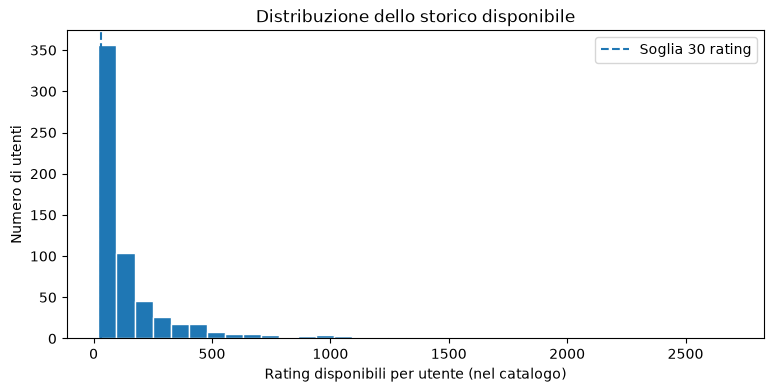

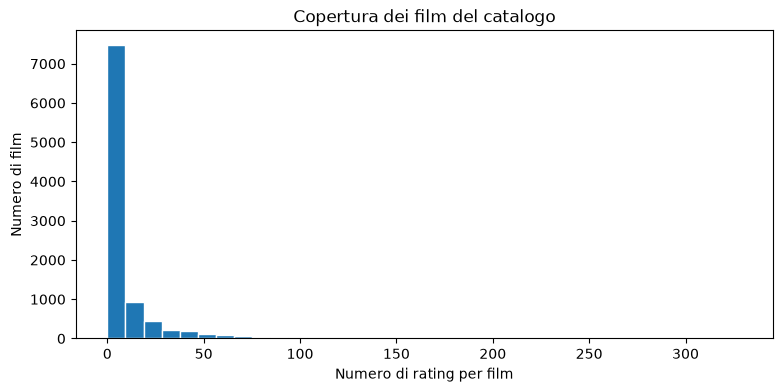

In [4]:
plt.figure(figsize=(9, 4))
plt.hist(per_user.n_ratings, bins=35, edgecolor="white")
plt.axvline(TOTAL_NEEDED, linestyle="--", label=f"Soglia {TOTAL_NEEDED} rating")
plt.xlabel("Rating disponibili per utente (nel catalogo)")
plt.ylabel("Numero di utenti")
plt.title("Distribuzione dello storico disponibile")
plt.legend()
plt.show()

plt.figure(figsize=(9, 4))
plt.hist(per_film.n_ratings, bins=35, edgecolor="white")
plt.xlabel("Numero di rating per film")
plt.ylabel("Numero di film")
plt.title("Copertura dei film del catalogo")
plt.show()

## 3. Idoneità dei profili 10/20

La condizione minima è `n_ratings >= 30`: i 10 del profilo e i 20 target sono rating di **qualsiasi classe**. Il ground truth deve però contenere **rating positivi osservati** per rendere informativi Recall/NDCG.

Non selezioniamo già gli utenti in base alle preferenze che finiranno nel target: l'esame dei positivi serve a stimare la fattibilità e successivamente a dichiarare criteri di inclusione fissati **prima** di eseguire il benchmark finale. La scelta può introdurre un bias verso utenti con molti rating positivi e andrà riportata.

In [5]:
thresholds = [1, 3, 5, 10, 20, 30, 40, 50, 75, 100]
eligibility = pd.DataFrame({
    "min_rating_utente": thresholds,
    "n_utenti": [int((per_user.n_ratings >= t).sum()) for t in thresholds],
})
eligibility["%_utenti_catalogo"] = (100 * eligibility.n_utenti / len(per_user)).round(1)
display(eligibility)

eligible_users = per_user.loc[per_user.n_ratings >= TOTAL_NEEDED].copy()
print(f"Utenti con almeno {TOTAL_NEEDED} rating: {len(eligible_users)} / {len(per_user)}")
print("Distribuzione totale delle classi tra gli utenti eleggibili (prima dello split):")
if len(eligible_users):
    display(eligible_users[["n_ratings", "n_pos", "n_mid", "n_neg", "positive_rate"]].describe().round(2))
    print("Casi con >=5 positivi totali:", int((eligible_users.n_pos >= 5).sum()))
    print("Casi con >=1 negativo totale:", int((eligible_users.n_neg >= 1).sum()))
else:
    print("ATTENZIONE: nessun utente eleggibile per il protocollo attuale 10/20")

,min_rating_utente,n_utenti,%_utenti_catalogo
0,1,610,100.0
1,3,610,100.0
2,5,610,100.0
3,10,610,100.0
4,20,610,100.0
5,30,501,82.1
6,40,428,70.2
7,50,385,63.1
8,75,298,48.9
9,100,248,40.7


Utenti con almeno 30 rating: 501 / 610
Distribuzione totale delle classi tra gli utenti eleggibili (prima dello split):


,n_ratings,n_pos,n_mid,n_neg,positive_rate
count,501.00,501.00,501.00,501.00,501.00
mean,196.07,94.03,75.79,26.25,0.56
std,288.34,115.71,145.17,62.80,0.20
min,30.00,3.00,0.00,0.00,0.07
25%,51.00,28.00,14.00,2.00,0.42
50%,98.00,50.00,28.00,8.00,0.58
75%,210.00,112.00,68.00,21.00,0.71
max,2698.00,1227.00,1604.00,684.00,0.96


Casi con >=5 positivi totali: 500
Casi con >=1 negativo totale: 439


## 4. Monte Carlo: fattibilità del ground truth **senza leakage**

Per ogni utente con almeno 30 rating facciamo una prova **puramente diagnostica**:

1. Campioniamo casualmente 30 rating tra tutti quelli disponibili per quell'utente, **senza usare il valore delle stelle nella selezione**.
2. Li dividiamo casualmente in **10 per il profilo** e **20 per il ground truth**.
3. Verifichiamo quanti target positivi/negativi sono nascosti, e quante preferenze sarebbero disponibili agli step 0,1,3,5,10.
4. Ripetiamo `N_REPEATS_AUDIT` volte e calcoliamo la percentuale di split con almeno 1/3/5 target positivi.

Il campionamento non è stratificato per rating: non forziamo profili positivi o target favorevoli. Il numero di rating nascosti è fisso; il set dei 20 rimarrà *identico fra i livelli* **all'interno di ogni futura simulazione**. Un'altra suddivisione casuale è una replica distinta, non un livello successivo della stessa simulazione.

**Importante:** questi split sono esplorativi; NON saranno riusati come split finali selezionando a posteriori quelli che producono prestazioni migliori.

In [6]:
rng = np.random.default_rng(SEED)
rows = []
for user_id, user_df in ratings.groupby("userId", sort=True):
    if len(user_df) < TOTAL_NEEDED:
        continue
    # Ordine canonico, indipendente dall'ordine del CSV.
    user_df = user_df.sort_values("movieId", kind="stable").reset_index(drop=True)
    classes = user_df["rating_class"].to_numpy()
    for repetition in range(N_REPEATS_AUDIT):
        selected = rng.choice(len(user_df), size=TOTAL_NEEDED, replace=False)
        perm = rng.permutation(TOTAL_NEEDED)
        profile_classes = classes[selected[perm[:N_PROFILE]]]
        gt_classes = classes[selected[perm[N_PROFILE:]]]
        rec = {
            "userId": int(user_id), "repeat": repetition,
            "user_ratings_catalog": len(user_df),
            "profile_pos": int(np.sum(profile_classes == "positivo")),
            "profile_mid": int(np.sum(profile_classes == "intermedio")),
            "profile_neg": int(np.sum(profile_classes == "negativo")),
            "gt_pos": int(np.sum(gt_classes == "positivo")),
            "gt_mid": int(np.sum(gt_classes == "intermedio")),
            "gt_neg": int(np.sum(gt_classes == "negativo")),
        }
        for k in LEVELS:
            prefix = profile_classes[:k]
            rec[f"prefix_{k}_pos"] = int(np.sum(prefix == "positivo"))
            rec[f"prefix_{k}_neg"] = int(np.sum(prefix == "negativo"))
        rows.append(rec)

split_probe = pd.DataFrame(rows)
if len(split_probe):
    assert (split_probe[["profile_pos", "profile_mid", "profile_neg"]].sum(axis=1) == N_PROFILE).all()
    assert (split_probe[["gt_pos", "gt_mid", "gt_neg"]].sum(axis=1) == N_GROUND_TRUTH).all()
    pass_rows = []
    for threshold in GT_POS_THRESHOLDS:
        user_pass = split_probe.groupby("userId")["gt_pos"].apply(lambda s: float((s >= threshold).mean()))
        pass_rows.append({
            "min_positivi_gt": threshold,
            "%_split_idonei": round(100 * (split_probe.gt_pos >= threshold).mean(), 1),
            "media_%_split_idonei_per_utente": round(100 * user_pass.mean(), 1),
            "utenti_con_almeno_80%_split_idonei": int((user_pass >= .8).sum()),
            "utenti_con_almeno_uno_split_idoneo": int((user_pass > 0).sum()),
        })
    pass_table = pd.DataFrame(pass_rows)
    display(pass_table)
    print("Statistiche dei rating nei 20 target nascosti:")
    display(split_probe[["gt_pos", "gt_mid", "gt_neg", "profile_pos", "profile_neg"]].describe().round(2))
    level_rows = []
    for k in LEVELS:
        level_rows.append({"rating_rivelati": k,
                           "%_profili_con_almeno_un_positivo": round(100*(split_probe[f"prefix_{k}_pos"] > 0).mean(), 1),
                           "%_profili_con_almeno_un_negativo": round(100*(split_probe[f"prefix_{k}_neg"] > 0).mean(), 1),
                           "%_profili_senza_positivi": round(100*(split_probe[f"prefix_{k}_pos"] == 0).mean(), 1)})
    level_table = pd.DataFrame(level_rows)
    display(level_table)
else:
    pass_table = pd.DataFrame(columns=["min_positivi_gt", "%_split_idonei"])
    level_table = pd.DataFrame(columns=["rating_rivelati"])
    print("Nessuno split generato: requisito 10/20 non soddisfatto sul catalogo")

,min_positivi_gt,%_split_idonei,media_%_split_idonei_per_utente,utenti_con_almeno_80%_split_idonei,utenti_con_almeno_uno_split_idoneo
0,1,99.7,99.7,499,501
1,3,97.7,97.7,485,501
2,5,92.5,92.5,442,497


Statistiche dei rating nei 20 target nascosti:


,gt_pos,gt_mid,gt_neg,profile_pos,profile_neg
count,15030.00,15030.00,15030.00,15030.00,15030.00
mean,11.23,6.58,2.19,5.63,1.10
std,4.36,3.60,2.48,2.40,1.41
min,0.00,0.00,0.00,0.00,0.00
25%,8.00,4.00,0.00,4.00,0.00
50%,12.00,6.00,1.00,6.00,1.00
75%,15.00,9.00,3.00,7.00,2.00
max,20.00,20.00,16.00,10.00,10.00


,rating_rivelati,%_profili_con_almeno_un_positivo,%_profili_con_almeno_un_negativo,%_profili_senza_positivi
0,0,0.0,0.0,100.0
1,1,56.1,10.4,43.9
2,3,86.6,26.1,13.4
3,5,94.4,37.7,5.6
4,10,98.6,54.3,1.4


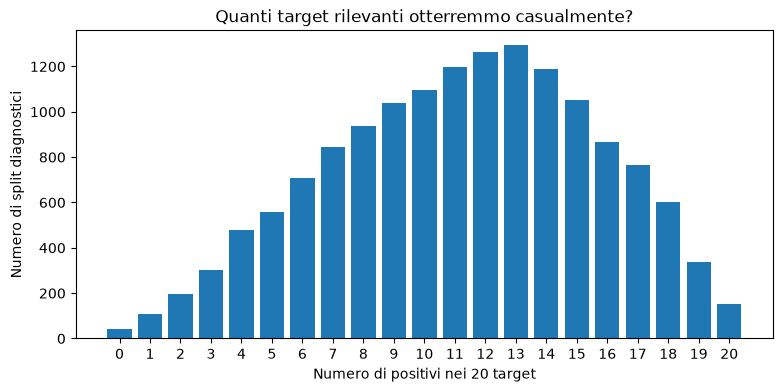

In [7]:
if not split_probe.empty:
    plt.figure(figsize=(9, 4))
    values = split_probe.gt_pos.value_counts().sort_index()
    plt.bar(values.index.astype(str), values.values)
    plt.xlabel(f"Numero di positivi nei {N_GROUND_TRUTH} target")
    plt.ylabel("Numero di split diagnostici")
    plt.title("Quanti target rilevanti otterremmo casualmente?")
    plt.show()

## 5. Copertura per **utenti mai visti** da Matrix Factorization

Per una valutazione di vero **new-user cold-start**, nessuna interazione degli utenti di validazione/test può contribuire all'addestramento dei fattori globali. Simuliamo una partizione **esplorativa** train/validation/test **a livello utente** (circa 80/10/10, stratificata soltanto per idoneità `>=30`):

- I fattori dei film MF verranno un giorno addestrati sui soli utenti **train**.
- Per un utente sconosciuto, un futuro algoritmo di **fold-in** stimerà il profilo personale utilizzando esclusivamente i rating progressivamente rivelati.
- I film del catalogo senza alcun rating tra gli utenti train non avranno un fattore collaborativo affidabile: l'audit misura quanti sono, **senza** inventare valori.

La stratificazione per idoneità si basa sul **numero** di interazioni, non sui target né sui risultati dei modelli. La divisione qui prodotta è solo una prova di copertura, non la suddivisione definitiva.

In [8]:
rng_partition = np.random.default_rng(SEED + 1)
all_user_ids = pd.DataFrame({"userId": sorted(ratings.userId.unique())})
all_user_ids["eligible_30"] = all_user_ids.userId.isin(set(eligible_users.userId))
assignment = []
for eligible_30, group in all_user_ids.groupby("eligible_30", sort=True):
    ids = group.userId.to_numpy().copy()
    rng_partition.shuffle(ids)
    n_test = int(round(len(ids) * .10))
    n_val = int(round(len(ids) * .10))
    for i, uid in enumerate(ids):
        split = "test" if i < n_test else "validation" if i < n_test + n_val else "train"
        assignment.append({"userId": int(uid), "split_preview": split, "eligible_30": bool(eligible_30)})
user_split_preview = pd.DataFrame(assignment).sort_values("userId")
print("Ripartizione utenti (audit, non definitiva):")
display(pd.crosstab(user_split_preview.split_preview, user_split_preview.eligible_30,
                   margins=True).rename(columns={False:"<30 rating", True:">=30 rating"}))

train_ids = set(user_split_preview.loc[user_split_preview.split_preview == "train", "userId"])
train_ratings = ratings.loc[ratings.userId.isin(train_ids)]
train_counts = train_ratings.groupby("movieId").size().reindex(catalog.movieId, fill_value=0)
train_known_ids = set(train_counts.loc[train_counts > 0].index)
train_test = ratings.merge(user_split_preview[["userId", "split_preview"]], on="userId", how="left")
coverage_rows = []
for split_name in ["train", "validation", "test"]:
    frame = train_test.loc[train_test.split_preview == split_name]
    positives = frame.loc[frame.rating_class == "positivo"]
    coverage_rows.append({
        "split": split_name,
        "utenti": frame.userId.nunique(),
        "rating": len(frame),
        "%_rating_su_item_visti_nel_training": round(100 * frame.movieId.isin(train_known_ids).mean(), 2) if len(frame) else np.nan,
        "%_positivi_su_item_visti_nel_training": round(100 * positives.movieId.isin(train_known_ids).mean(), 2) if len(positives) else np.nan,
    })
coverage_table = pd.DataFrame(coverage_rows)
display(coverage_table)
print(f"Film con almeno 1 rating TRAIN: {len(train_known_ids):,} / {len(catalog):,}")
for t in (1, 2, 5, 10, 20):
    print(f"Film con almeno {t} rating train: {(train_counts >= t).sum():,}")
print("Nota: le quote di copertura sopra NON sono misure di accuracy; indicano solo fattibilità MF.")

Ripartizione utenti (audit, non definitiva):


eligible_30,<30 rating,>=30 rating,All
split_preview,,,
test,11,50,61
train,87,401,488
validation,11,50,61
All,109,501,610


,split,utenti,rating,%_rating_su_item_visti_nel_training,%_positivi_su_item_visti_nel_training
0,train,488,85776,100.00,100.00
1,validation,61,6668,96.57,95.21
2,test,61,8392,97.59,98.03


Film con almeno 1 rating TRAIN: 9,306 / 9,742
Film con almeno 1 rating train: 9,306
Film con almeno 2 rating train: 5,998
Film con almeno 5 rating train: 3,410
Film con almeno 10 rating train: 2,071
Film con almeno 20 rating train: 1,126
Nota: le quote di copertura sopra NON sono misure di accuracy; indicano solo fattibilità MF.


## 6. Sensibilità temporale (diagnostica)

Con timestamp disponibili, valutiamo una possibile divisione basata sulla **cronologia dei rating**: tra gli ultimi 30 rating dell'utente, i 10 più vecchi servono per il profilo e i 20 più recenti come target. Ciò evita che rating successivi aiutino a predire quelli precedenti; il timestamp del rating **non** equivale necessariamente alla data di visione.

Confrontiamo questa diagnosi con il campionamento casuale senza scegliere ora il protocollo finale.

In [9]:
temporal_rows = []
if "timestamp" in ratings and ratings.timestamp.notna().all():
    for user_id, group in ratings.groupby("userId", sort=True):
        if len(group) < TOTAL_NEEDED:
            continue
        window = group.sort_values(["timestamp", "movieId"], kind="stable").tail(TOTAL_NEEDED)
        prof = window.head(N_PROFILE).rating_class
        gt = window.tail(N_GROUND_TRUTH).rating_class
        temporal_rows.append({"userId": int(user_id),
                              "profile_pos": int((prof == "positivo").sum()),
                              "profile_neg": int((prof == "negativo").sum()),
                              "gt_pos": int((gt == "positivo").sum()),
                              "gt_neg": int((gt == "negativo").sum())})
    temporal_probe = pd.DataFrame(temporal_rows)
    if not temporal_probe.empty:
        temporal_compare = pd.DataFrame({
            "min_positivi_gt": list(GT_POS_THRESHOLDS),
            "%_utenti_idonei_temporale": [round(100 * (temporal_probe.gt_pos >= x).mean(), 1)
                                          for x in GT_POS_THRESHOLDS],
            "%_split_idonei_casuale": [round(100 * (split_probe.gt_pos >= x).mean(), 1)
                                        for x in GT_POS_THRESHOLDS]
        })
        display(temporal_compare)
else:
    temporal_probe = pd.DataFrame(columns=["userId", "profile_pos", "gt_pos"])
    print("Timestamp non presenti/validi: analisi temporale saltata")

,min_positivi_gt,%_utenti_idonei_temporale,%_split_idonei_casuale
0,1,97.8,99.7
1,3,92.6,97.7
2,5,85.8,92.5


## 7. Tag MovieLens (diagnostica secondaria)

I tag non sono necessariamente preferenze positive: per esempio `In Netflix queue` indica un'intenzione/organizzazione, non un rating. Qui verifichiamo se nel catalogo esistono segnali utili per una futura simulazione LLM e quanti utenti distinti li hanno inseriti. **Non** usiamo i tag per selezionare i target positivi.

> Attenzione al leakage dei documenti già arricchiti: nel notebook 02 `ml_tags`, `ml_rating_mean`, `ml_tag_text` e `text_combined` sono stati costruiti prima di separare utenti di training/test. Se usiamo queste colonne nei futuri embedding GTE o come feature del recommender, rischiamo informazioni derivate dai test users. L'audit non le modifica: segnala soltanto il rischio.

In [10]:
tag_summary = pd.DataFrame()
queue_summary = pd.DataFrame()
if tags_all is not None and {"userId", "movieId", "tag"}.issubset(tags_all.columns):
    tags_all["movieId"] = pd.to_numeric(tags_all.movieId, errors="raise").astype("int64")
    tags_all["userId"] = pd.to_numeric(tags_all.userId, errors="raise").astype("int64")
    tags_cat = tags_all.loc[tags_all.movieId.isin(catalog_ids)].copy()
    tags_cat["tag_clean"] = tags_cat.tag.fillna("").astype(str).str.strip().str.casefold()
    tag_summary = (tags_cat.groupby("tag_clean").agg(n_tags=("tag_clean", "size"),
                 n_users=("userId", "nunique"), n_films=("movieId", "nunique"))
                 .sort_values("n_tags", ascending=False).head(20).reset_index())
    print("Tag: completo", len(tags_all), "| nel catalogo", len(tags_cat),
          "| utenti distinti nel catalogo", tags_cat.userId.nunique())
    display(tag_summary)
    q = tags_cat.loc[tags_cat.tag_clean == "in netflix queue"].copy()
    tagged_pairs = q[["userId", "movieId"]].drop_duplicates()
    rated_pairs = ratings[["userId", "movieId"]].drop_duplicates()
    pairs_also_rated = tagged_pairs.merge(rated_pairs, on=["userId", "movieId"], how="inner")
    queue_summary = pd.DataFrame([{
        "tag": "In Netflix queue",
        "applicazioni_nel_catalogo": len(q),
        "utenti_distinti": q.userId.nunique(),
        "film_distinti": q.movieId.nunique(),
        "coppie_utente_film_anche_votate": len(pairs_also_rated),
    }])
    display(queue_summary)
else:
    print("tags.csv assente oppure incompleto: diagnostica tag saltata")

leakage_cols = [c for c in ["ml_tags", "ml_tag_text", "ml_tag_weights", "ml_rating_mean",
                             "ml_rating_count", "ml_weighted_rating", "text_movielens", "text_combined"]
                if c in catalog.columns]
print("Colonne derivate da interazioni MovieLens presenti nel catalogo:", leakage_cols)
print("ATTENZIONE: non usare tali colonne per costruire embedding del benchmark senza filtrare i test users.")

Tag: completo 3683 | nel catalogo 3683 | utenti distinti nel catalogo 58


,tag_clean,n_tags,n_users,n_films
0,in netflix queue,131,1,131
1,atmospheric,41,10,37
2,thought-provoking,24,7,19
3,surreal,24,6,22
4,funny,24,10,22
5,superhero,24,7,22
6,disney,23,3,22
7,sci-fi,23,10,19
8,quirky,22,5,22
9,religion,22,2,22


,tag,applicazioni_nel_catalogo,utenti_distinti,film_distinti,coppie_utente_film_anche_votate
0,In Netflix queue,131,1,131,55


Colonne derivate da interazioni MovieLens presenti nel catalogo: ['ml_tags', 'ml_tag_text', 'ml_tag_weights', 'ml_rating_mean', 'ml_rating_count', 'ml_weighted_rating', 'text_movielens', 'text_combined']
ATTENZIONE: non usare tali colonne per costruire embedding del benchmark senza filtrare i test users.


## 8. Export risultati e checklist decisionale

Salviamo soltanto **statistiche diagnostiche**, non il modello e non gli split ufficiali. Lo scopo è discutere i risultati e poi decidere formalmente:

- catalogo attuale o espansione;
- soglia minima di target positivi e numero di utenti;
- split casuale ripetuto o temporale;
- protocollo train/validation/test a utenti disgiunti;
- scelta e implementazione di Matrix Factorization con **fold-in**.

**Importante:** gli utenti con >=30 rating non sono automaticamente tutti adatti: i 20 target devono includere sufficienti preferenze positive, e un eventuale criterio di idoneità può alterare la popolazione studiata. Per i successivi esperimenti le distribuzioni delle classi e la copertura per film vanno documentate.

In [12]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
exports = {
    "audit_user_statistics.csv": per_user,
    "audit_movie_statistics.csv": per_film,
    "audit_min_history_thresholds.csv": eligibility,
    "audit_random_split_probe.csv": split_probe,
    "audit_random_split_feasibility.csv": pass_table,
    "audit_history_level_feasibility.csv": level_table,
    "audit_user_split_preview.csv": user_split_preview,
    "audit_train_item_coverage.csv": coverage_table,
    "audit_temporal_probe.csv": temporal_probe,
    "audit_top_tags.csv": tag_summary,
    "audit_netflix_queue.csv": queue_summary,
}
for name, df in exports.items():
    df.to_csv(OUT_DIR / name, index=False)

def sha256_file(path):
    dig = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(2**20), b""):
            dig.update(chunk)
    return dig.hexdigest()

manifest = {
    "seed": SEED,
    "n_profile": N_PROFILE,
    "n_ground_truth": N_GROUND_TRUTH,
    "levels": list(LEVELS),
    "n_repeats_audit": N_REPEATS_AUDIT,
    "positive_threshold_gte": POS_THRESHOLD,
    "negative_threshold_lte": NEG_THRESHOLD,
    "movies_catalog": len(catalog),
    "ratings_catalog": len(ratings),
    "users_catalog": n_users,
    "eligible_users_gte_30": len(eligible_users),
    "possible_leakage_columns": leakage_cols,
    "inputs": {"ratings.csv": sha256_file(RATING_PATH),
               "catalog_enriched.csv": sha256_file(CATALOG_PATH)},
    "note": "Split diagnostici, NON divisioni finali. Non addestra alcun RS."
}
(OUT_DIR / "audit_manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")

summary = [
    "# Audit di fattibilità MovieLens — recommendation cold-start", "",
    "## Configurazione", "",
    f"- Catalogo effettivo: **{len(catalog)} film**", 
    f"- Rating nel catalogo: **{len(ratings)}** / {len(ratings_all)} globali",
    f"- Utenti con almeno {TOTAL_NEEDED} rating: **{len(eligible_users)}** / {len(per_user)}",
    f"- Protocollo diagnosticato: **{N_PROFILE} profilo / {N_GROUND_TRUTH} ground truth**",
    f"- Ripetizioni casuali di audit per utente: **{N_REPEATS_AUDIT}**; seed **{SEED}**", "",
    "## Positivi nel ground truth (simulazione casuale)", "",
]
def markdown_table(df):
    # Nessuna dipendenza da tabulate (facoltativa in pandas).
    names = [str(c) for c in df.columns]
    out = ["| " + " | ".join(names) + " |", "| " + " | ".join(["---"]*len(names)) + " |"]
    for row in df.itertuples(index=False, name=None):
        out.append("| " + " | ".join(str(v) for v in row) + " |")
    return "\n".join(out)

if not pass_table.empty:
    summary += [markdown_table(pass_table), ""]
if not level_table.empty:
    summary += ["## Segnali disponibili per livello", "", markdown_table(level_table), ""]
summary += [
    "## Copertura item del training diagnostico", "",
    f"- Film con almeno un rating nel training esplorativo: **{len(train_known_ids)} / {len(catalog)}**", "",
    "## Decisioni ancora aperte", "",
    "1. Confermare 10/20 oppure adattare ai dati, fissando i criteri sul validation protocol prima del test finale.",
    "2. Scegliere random split ripetuto o split cronologico (anche come analisi di sensibilità).",
    "3. Congelare una divisione utenti disgiunti train/validation/test; non addestrare MF sugli utenti test.",
    "4. Definire fallback quando MF/GTE non hanno segnali o item coperti.",
    "5. Usare metadata descrittivi TMDb senza colonne aggregative MovieLens create con i dati dei test users.",
    "6. Separare i target positivi osservati dai film senza rating: assenza di voto non significa avversione.",
    "", "_Questo audit NON contiene valutazioni MF/GTE o risultati di recommendation._", ""
]
(OUT_DIR / "audit_readme.md").write_text("\n".join(summary), encoding="utf-8")
print(f"Esportati {len(exports)} CSV e 2 file riepilogativi in {OUT_DIR}")
print("File principali: audit_user_statistics.csv, audit_random_split_feasibility.csv, audit_readme.md")
display(Markdown("\n".join(summary[:15])))

Esportati 11 CSV e 2 file riepilogativi in /Users/danieleraveglia/Documents/uniMi/TESI/progetto/datasets/processed/recommendation_audit_v2
File principali: audit_user_statistics.csv, audit_random_split_feasibility.csv, audit_readme.md


# Audit di fattibilità MovieLens — recommendation cold-start

## Configurazione

- Catalogo effettivo: **9742 film**
- Rating nel catalogo: **100836** / 100836 globali
- Utenti con almeno 30 rating: **501** / 610
- Protocollo diagnosticato: **10 profilo / 20 ground truth**
- Ripetizioni casuali di audit per utente: **30**; seed **20261021**

## Positivi nel ground truth (simulazione casuale)

| min_positivi_gt | %_split_idonei | media_%_split_idonei_per_utente | utenti_con_almeno_80%_split_idonei | utenti_con_almeno_uno_split_idoneo |
| --- | --- | --- | --- | --- |
| 1 | 99.7 | 99.7 | 499 | 501 |
| 3 | 97.7 | 97.7 | 485 | 501 |
| 5 | 92.5 | 92.5 | 442 | 497 |

## Segnali disponibili per livello

## 9. Come leggere i risultati e scegliere il prossimo passo

1. **`audit_min_history_thresholds.csv`**: quanti utenti possono sostenere 10/20; se pochi, considerare un protocollo più piccolo *prima* di espandere il catalogo.
2. **`audit_random_split_feasibility.csv`**: quanto spesso 20 rating nascosti contengono almeno 3/5 positivi **senza scegliere i target in base alle stelle**.
3. **`audit_history_level_feasibility.csv`**: quanto spesso, con soli 1–3 rating rivelati, si dispone effettivamente di un esempio positivo/negativo. Serve per pianificare fallback GTE e per interpretare la difficoltà di MF con fold-in.
4. **`audit_train_item_coverage.csv`**: verifica che i film destinati al ranking siano appresi da un modello collaborativo addestrato su altri utenti; per gli item senza training predisporre fallback e dichiarare la copertura.
5. **`audit_temporal_probe.csv`**: confronto preliminare tra split cronologico e casuale.

**Dopo l'audit:** inviami `audit_readme.md` (e, se serve, gli altri CSV) oppure incolla qui le tabelle prodotte. Decideremo insieme se restare sui 2.000 film, come congelare gli split finali e poi realizzeremo un **prototipo minimo di Matrix Factorization con fold-in**. Il notebook non ha bisogno di Qdrant, TMDb API, Gemini o GPU.